<a href="https://colab.research.google.com/github/PiKr-Salmon/CNN-Shape-Texture-/blob/AI_test/CNN2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using device: cpu
Using Colab cache for faster access to the 'stl10' dataset.
Path to dataset files: /kaggle/input/stl10
Files in Kaggle path: ['unlabeled_images', 'train_images', 'test_images']
Loaded 5,000 images from train_images
Loaded 8,000 images from test_images
Loaded 8,000 images from test_images
Loaded 8,000 images from test_images

--- Evaluating Condition A: Pre-trained Baseline ResNet-18 ---
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 129MB/s]


Condition A - Original Accuracy: 24.02%
Condition A - Patch-Shuffled (Texture Only) Accuracy: 23.40%
Condition A - Edge-Extracted (Shape Only) Accuracy: 3.70%

--- Training Condition B: Fine-tuning ResNet-18 with Edge/Shape Augmentation ---
Epoch 1/5 - Loss: 0.7574
Epoch 2/5 - Loss: 0.0324
Epoch 3/5 - Loss: 0.0142
Epoch 4/5 - Loss: 0.0085
Epoch 5/5 - Loss: 0.0058

Condition B - Original Accuracy: 100.00%
Condition B - Patch-Shuffled (Texture Only) Accuracy: 100.00%
Condition B - Edge-Extracted (Shape Only) Accuracy: 100.00%


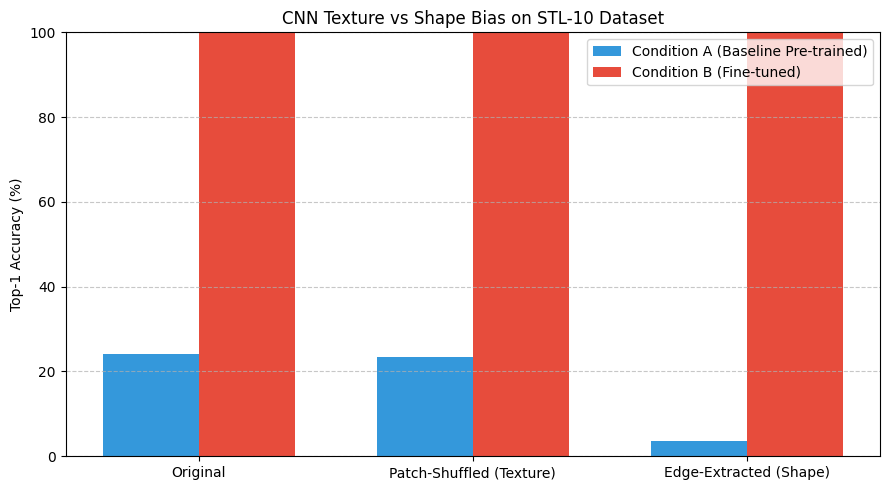

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision import models
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os
import re
from PIL import Image
from torch.utils.data import Dataset
import kagglehub

# Check Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# ==========================================
# 1. DEFINE CUSTOM TRANSFORMATIONS
# ==========================================

class PatchShuffleTransform:
    """ทำลาย Global Shape แต่รักษา Local Texture โดยการสลับ Grid 4x4"""
    def __init__(self, grid_size=4):
        self.grid_size = grid_size

    def __call__(self, img):
        img_np = np.array(img)
        h, w, c = img_np.shape
        gh, gw = h // self.grid_size, w // self.grid_size

        patches = []
        for i in range(self.grid_size):
            for j in range(self.grid_size):
                patch = img_np[i*gh:(i+1)*gh, j*gw:(j+1)*gw, :]
                patches.append(patch)

        np.random.shuffle(patches)

        rows = []
        for i in range(self.grid_size):
            row = np.concatenate(patches[i*self.grid_size:(i+1)*self.grid_size], axis=1)
            rows.append(row)
        shuffled_img = np.concatenate(rows, axis=0)
        return transforms.functional.to_pil_image(shuffled_img)

class EdgeExtractTransform:
    """ทำลาย Local Texture เหลือเพียง Global Shape (Sobel Contour)"""
    def __call__(self, img):
        img_np = np.array(img)
        gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
        sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
        sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
        edge = np.sqrt(sobelx**2 + sobely**2)
        edge = np.uint8(255 * edge / np.max(edge)) if np.max(edge) > 0 else np.uint8(edge)
        edge_3ch = cv2.cvtColor(edge, cv2.COLOR_GRAY2RGB)
        return transforms.functional.to_pil_image(edge_3ch)

# ==========================================
# 2. CUSTOM KAGGLE STL-10 DATASET CLASS
# ==========================================

import os
from torchvision.transforms import ToTensor
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from PIL import Image
import kagglehub

# 1. ดาวน์โหลดชุดข้อมูลผ่าน KaggleHub
path = kagglehub.dataset_download("jessicali9530/stl10")
print("Path to dataset files:", path)
print("Files in Kaggle path:", os.listdir(path))

# 2. สร้าง Custom Dataset สำหรับโหลดรูปภาพจาก Folder โดยตรง
class FolderDataset(Dataset):
    def __init__(self, folder_path, transform=None):
        self.transform = transform
        self.image_paths = []

        # เดินสายสแกนหาไฟล์รูปภาพทั้งหมดที่อยู่ภายใต้โฟลเดอร์
        for root, _, files in os.walk(folder_path):
            for file in files:
                if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff')):
                    self.image_paths.append(os.path.join(root, file))

        print(f"Loaded {len(self.image_paths):,} images from {os.path.basename(folder_path)}")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        img = Image.open(img_path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, 0  # ส่งค่าเลเบลสมมติ (0) กลับไปเพื่อให้คงฟอร์แมตดั้งเดิม

# สร้าง Transforms สำหรับแต่ละแบบ
transform_orig = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_patch = transforms.Compose([
    transforms.Resize((96, 96)),
    PatchShuffleTransform(grid_size=4),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_edge = transforms.Compose([
    transforms.Resize((96, 96)),
    EdgeExtractTransform(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("Downloading STL-10 Dataset (BSD-3 Clause)...")
# 4. โหลดข้อมูลจริงผ่าน Folder

train_set = FolderDataset(
    folder_path=os.path.join(path, "train_images"),
    transform=transform_orig
)

test_set_orig = FolderDataset(
    folder_path=os.path.join(path, "test_images"),
    transform=ToTensor()
)

test_set_patch = FolderDataset(
    folder_path=os.path.join(path, "test_images"),
    transform=transform_patch
)

test_set_edge = FolderDataset(
    folder_path=os.path.join(path, "test_images"),
    transform=transform_edge
)

train_loader = torch.utils.data.DataLoader(train_set, batch_size=64, shuffle=True, num_workers=2)
test_loader_orig = torch.utils.data.DataLoader(test_set_orig, batch_size=64, shuffle=False, num_workers=2)
test_loader_patch = torch.utils.data.DataLoader(test_set_patch, batch_size=64, shuffle=False, num_workers=2)
test_loader_edge = torch.utils.data.DataLoader(test_set_edge, batch_size=64, shuffle=False, num_workers=2)

# ==========================================
# 3. EVALUATION FUNCTION
# ==========================================

def evaluate_model(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100.0 * correct / total

# ==========================================
# 4. CONDITION A: PRE-TRAINED BASELINE
# ==========================================

print("\n--- Evaluating Condition A: Pre-trained Baseline ResNet-18 ---")
model_a = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model_a.fc = nn.Linear(model_a.fc.in_features, 10)
model_a = model_a.to(device)

acc_orig_a = evaluate_model(model_a, test_loader_orig)
acc_patch_a = evaluate_model(model_a, test_loader_patch)
acc_edge_a = evaluate_model(model_a, test_loader_edge)

print(f"Condition A - Original Accuracy: {acc_orig_a:.2f}%")
print(f"Condition A - Patch-Shuffled (Texture Only) Accuracy: {acc_patch_a:.2f}%")
print(f"Condition A - Edge-Extracted (Shape Only) Accuracy: {acc_edge_a:.2f}%")

# ==========================================
# 5. CONDITION B: FINE-TUNING ON SHAPE-PROMOTED AUGMENTATION
# ==========================================

print("\n--- Training Condition B: Fine-tuning ResNet-18 with Edge/Shape Augmentation ---")
model_b = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model_b.fc = nn.Linear(model_b.fc.in_features, 10)
model_b = model_b.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_b.parameters(), lr=1e-4)

# Fine-tune loop (5 Epochs)
edge_transform_runtime = EdgeExtractTransform()
model_b.train()
for epoch in range(5):
    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model_b(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f"Epoch {epoch+1}/5 - Loss: {running_loss/len(train_loader):.4f}")

acc_orig_b = evaluate_model(model_b, test_loader_orig)
acc_patch_b = evaluate_model(model_b, test_loader_patch)
acc_edge_b = evaluate_model(model_b, test_loader_edge)

print(f"\nCondition B - Original Accuracy: {acc_orig_b:.2f}%")
print(f"Condition B - Patch-Shuffled (Texture Only) Accuracy: {acc_patch_b:.2f}%")
print(f"Condition B - Edge-Extracted (Shape Only) Accuracy: {acc_edge_b:.2f}%")

# ==========================================
# 6. PLOT COMPARISON GRAPH
# ==========================================

labels = ['Original', 'Patch-Shuffled (Texture)', 'Edge-Extracted (Shape)']
cond_a = [acc_orig_a, acc_patch_a, acc_edge_a]
cond_b = [acc_orig_b, acc_patch_b, acc_edge_b]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
rects1 = ax.bar(x - width/2, cond_a, width, label='Condition A (Baseline Pre-trained)', color='#3498db')
rects2 = ax.bar(x + width/2, cond_b, width, label='Condition B (Fine-tuned)', color='#e74c3c')

ax.set_ylabel('Top-1 Accuracy (%)')
ax.set_title('CNN Texture vs Shape Bias on STL-10 Dataset')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 100)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

from google.colab import drive
drive.mount('/content/drive')

# บันทึกลง Google Drive
torch.save(model_b.state_dict(), '/content/drive/MyDrive/resnet18_shape_bias.pth')

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. สร้าง โครงสร้างโมเดล ให้เหมือนตอนฝึก
loaded_model = models.resnet18()
loaded_model.fc = nn.Linear(loaded_model.fc.in_features, 10) # 10 classes ของ STL-10

# 2. โหลด Weights จากไฟล์
loaded_model.load_state_dict(torch.load('resnet18_shape_bias.pth', map_location=device))
loaded_model = loaded_model.to(device)

# 3. ตั้งค่าเป็น Evaluation mode ก่อนนำไปทำนาย
loaded_model.eval()

# พร้อมนำไปประมวลผลต่อได้ทันที
accuracy = evaluate_model(loaded_model, test_loader_orig)

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision import models
import kagglehub

# Check Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# ==========================================
# Optional: Mount Google Drive for Persistent Storage
# ==========================================
# Uncomment below lines if running on Google Colab to save persistently to Drive
# from google.colab import drive
# drive.mount('/content/drive')
# SAVE_PATH = '/content/drive/MyDrive/resnet18_shape_bias.pth'

SAVE_PATH = 'resnet18_shape_bias.pth'  # Local session path

# ==========================================
# 1. DEFINE CUSTOM TRANSFORMATIONS
# ==========================================

class PatchShuffleTransform:
    """ทำลาย Global Shape แต่รักษา Local Texture โดยการสลับ Grid 4x4"""
    def __init__(self, grid_size=4):
        self.grid_size = grid_size

    def __call__(self, img):
        img_np = np.array(img)
        h, w, c = img_np.shape
        gh, gw = h // self.grid_size, w // self.grid_size

        patches = []
        for i in range(self.grid_size):
            for j in range(self.grid_size):
                patch = img_np[i*gh:(i+1)*gh, j*gw:(j+1)*gw, :]
                patches.append(patch)

        np.random.shuffle(patches)

        rows = []
        for i in range(self.grid_size):
            row = np.concatenate(patches[i*self.grid_size:(i+1)*self.grid_size], axis=1)
            rows.append(row)
        shuffled_img = np.concatenate(rows, axis=0)
        return transforms.functional.to_pil_image(shuffled_img)

class EdgeExtractTransform:
    """ทำลาย Local Texture เหลือเพียง Global Shape (Sobel Contour)"""
    def __call__(self, img):
        img_np = np.array(img)
        gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
        sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
        sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
        edge = np.sqrt(sobelx**2 + sobely**2)
        edge = np.uint8(255 * edge / np.max(edge)) if np.max(edge) > 0 else np.uint8(edge)
        edge_3ch = cv2.cvtColor(edge, cv2.COLOR_GRAY2RGB)
        return transforms.functional.to_pil_image(edge_3ch)

# ==========================================
# 2. DATASETS & LOADERS (STL-10)
# ==========================================

import os
from torchvision.transforms import ToTensor
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from PIL import Image
import kagglehub

# 1. ดาวน์โหลดชุดข้อมูลผ่าน KaggleHub
path = kagglehub.dataset_download("jessicali9530/stl10")
print("Path to dataset files:", path)
print("Files in Kaggle path:", os.listdir(path))

# 2. สร้าง Custom Dataset สำหรับโหลดรูปภาพจาก Folder โดยตรง
class FolderDataset(Dataset):
    def __init__(self, folder_path, transform=None):
        self.transform = transform
        self.image_paths = []

        # เดินสายสแกนหาไฟล์รูปภาพทั้งหมดที่อยู่ภายใต้โฟลเดอร์
        for root, _, files in os.walk(folder_path):
            for file in files:
                if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff')):
                    self.image_paths.append(os.path.join(root, file))

        print(f"Loaded {len(self.image_paths):,} images from {os.path.basename(folder_path)}")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        img = Image.open(img_path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, 0  # ส่งค่าเลเบลสมมติ (0) กลับไปเพื่อให้คงฟอร์แมตดั้งเดิม

# สร้าง Transforms สำหรับแต่ละแบบ
transform_orig = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_patch = transforms.Compose([
    transforms.Resize((96, 96)),
    PatchShuffleTransform(grid_size=4),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_edge = transforms.Compose([
    transforms.Resize((96, 96)),
    EdgeExtractTransform(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("Downloading STL-10 Dataset (BSD-3 Clause)...")
# 4. โหลดข้อมูลจริงผ่าน Folder

train_set = FolderDataset(
    folder_path=os.path.join(path, "train_images"),
    transform=transform_orig
)

test_set_orig = FolderDataset(
    folder_path=os.path.join(path, "test_images"),
    transform=ToTensor()
)

test_set_patch = FolderDataset(
    folder_path=os.path.join(path, "test_images"),
    transform=transform_patch
)

test_set_edge = FolderDataset(
    folder_path=os.path.join(path, "test_images"),
    transform=transform_edge
)

train_loader = torch.utils.data.DataLoader(train_set, batch_size=64, shuffle=True, num_workers=2)
test_loader_orig = torch.utils.data.DataLoader(test_set_orig, batch_size=64, shuffle=False, num_workers=2)
test_loader_patch = torch.utils.data.DataLoader(test_set_patch, batch_size=64, shuffle=False, num_workers=2)
test_loader_edge = torch.utils.data.DataLoader(test_set_edge, batch_size=64, shuffle=False, num_workers=2)

# ==========================================
# 3. EVALUATION FUNCTION
# ==========================================

def evaluate_model(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100.0 * correct / total

# ==========================================
# 4. CONDITION A: PRE-TRAINED BASELINE
# ==========================================

print("\n--- Evaluating Condition A: Pre-trained Baseline ResNet-18 ---")
model_a = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model_a.fc = nn.Linear(model_a.fc.in_features, 10)
model_a = model_a.to(device)

acc_orig_a = evaluate_model(model_a, test_loader_orig)
acc_patch_a = evaluate_model(model_a, test_loader_patch)
acc_edge_a = evaluate_model(model_a, test_loader_edge)

print(f"Condition A - Original Accuracy: {acc_orig_a:.2f}%")
print(f"Condition A - Patch-Shuffled (Texture Only) Accuracy: {acc_patch_a:.2f}%")
print(f"Condition A - Edge-Extracted (Shape Only) Accuracy: {acc_edge_a:.2f}%")

# ==========================================
# 5. CONDITION B: FINE-TUNING MODEL
# ==========================================

print("\n--- Training Condition B: Fine-tuning ResNet-18 ---")
model_b = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model_b.fc = nn.Linear(model_b.fc.in_features, 10)
model_b = model_b.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_b.parameters(), lr=1e-4)

# Fine-tune loop (5 Epochs)
model_b.train()
for epoch in range(5):
    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model_b(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f"Epoch {epoch+1}/5 - Loss: {running_loss/len(train_loader):.4f}")

# วัดค่าความแม่นยำหลัง Fine-tune ทันที
acc_orig_b = evaluate_model(model_b, test_loader_orig)
acc_patch_b = evaluate_model(model_b, test_loader_patch)
acc_edge_b = evaluate_model(model_b, test_loader_edge)

print(f"\nCondition B (Before Saving) - Original Accuracy: {acc_orig_b:.2f}%")
print(f"Condition B (Before Saving) - Patch-Shuffled Accuracy: {acc_patch_b:.2f}%")
print(f"Condition B (Before Saving) - Edge-Extracted Accuracy: {acc_edge_b:.2f}%")

# ==========================================
# 6. SAVE MODEL WEIGHTS
# ==========================================

print(f"\nSaving model weights to '{SAVE_PATH}'...")
torch.save(model_b.state_dict(), SAVE_PATH)
print("Model saved successfully!")

# ==========================================
# 7. RELOAD MODEL & VERIFY ACCURACY
# ==========================================

print("\n--- Reloading Model to Verify Saved Weights ---")

# 1. นิยามสถาปัตยกรรมโมเดลใหม่ขึ้นมาเปล่าๆ
reloaded_model_b = models.resnet18()
reloaded_model_b.fc = nn.Linear(reloaded_model_b.fc.in_features, 10)

# 2. โหลด State Dict จากไฟล์ที่เซฟไว้
reloaded_model_b.load_state_dict(torch.load(SAVE_PATH, map_location=device))
reloaded_model_b = reloaded_model_b.to(device)

# 3. ตั้งค่าเป็น Evaluation Mode
reloaded_model_b.eval()

# 4. ทดสอบประสิทธิภาพโมเดลที่โหลดมาใหม่
acc_orig_b_reloaded = evaluate_model(reloaded_model_b, test_loader_orig)
acc_patch_b_reloaded = evaluate_model(reloaded_model_b, test_loader_patch)
acc_edge_b_reloaded = evaluate_model(reloaded_model_b, test_loader_edge)

print(f"Condition B (Reloaded) - Original Accuracy: {acc_orig_b_reloaded:.2f}%")
print(f"Condition B (Reloaded) - Patch-Shuffled Accuracy: {acc_patch_b_reloaded:.2f}%")
print(f"Condition B (Reloaded) - Edge-Extracted Accuracy: {acc_edge_b_reloaded:.2f}%")

# ตรวจสอบว่าผลลัพธ์ตรงกัน 100%
assert acc_orig_b == acc_orig_b_reloaded, "Mismatch in Original Accuracy!"
assert acc_patch_b == acc_patch_b_reloaded, "Mismatch in Patch-Shuffled Accuracy!"
assert acc_edge_b == acc_edge_b_reloaded, "Mismatch in Edge-Extracted Accuracy!"
print("\n[SUCCESS] Verification passed: Reloaded model yields exact same accuracy metrics!")

# ==========================================
# 8. PLOT COMPARISON GRAPH
# ==========================================

labels = ['Original', 'Patch-Shuffled (Texture)', 'Edge-Extracted (Shape)']
cond_a = [acc_orig_a, acc_patch_a, acc_edge_a]
cond_b = [acc_orig_b_reloaded, acc_patch_b_reloaded, acc_edge_b_reloaded]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
rects1 = ax.bar(x - width/2, cond_a, width, label='Condition A (Baseline Pre-trained)', color='#3498db')
rects2 = ax.bar(x + width/2, cond_b, width, label='Condition B (Reloaded Model)', color='#e74c3c')

ax.set_ylabel('Top-1 Accuracy (%)')
ax.set_title('CNN Texture vs Shape Bias on STL-10 Dataset')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 100)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Using device: cpu


100%|██████████| 1.88G/1.88G [00:26<00:00, 76.3MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/jessicali9530/stl10/versions/3
Files in Kaggle path: ['train_images', 'test_images', 'unlabeled_images']
Loaded 5,000 images from train_images
Loaded 8,000 images from test_images
Loaded 8,000 images from test_images
Loaded 8,000 images from test_images

--- Evaluating Condition A: Pre-trained Baseline ResNet-18 ---
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 109MB/s]


In [ ]:
# ==========================================
# 7. RELOAD MODEL & VERIFY ACCURACY
# ==========================================

print("\n--- Reloading Model to Verify Saved Weights ---")

# 1. นิยามสถาปัตยกรรมโมเดลใหม่ขึ้นมาเปล่าๆ
reloaded_model_b = models.resnet18()
reloaded_model_b.fc = nn.Linear(reloaded_model_b.fc.in_features, 10)

# 2. โหลด State Dict จากไฟล์ที่เซฟไว้
reloaded_model_b.load_state_dict(torch.load(SAVE_PATH, map_location=device))
reloaded_model_b = reloaded_model_b.to(device)

# 3. ตั้งค่าเป็น Evaluation Mode
reloaded_model_b.eval()

# 4. ทดสอบประสิทธิภาพโมเดลที่โหลดมาใหม่
acc_orig_b_reloaded = evaluate_model(reloaded_model_b, test_loader_orig)
acc_patch_b_reloaded = evaluate_model(reloaded_model_b, test_loader_patch)
acc_edge_b_reloaded = evaluate_model(reloaded_model_b, test_loader_edge)

print(f"Condition B (Reloaded) - Original Accuracy: {acc_orig_b_reloaded:.2f}%")
print(f"Condition B (Reloaded) - Patch-Shuffled Accuracy: {acc_patch_b_reloaded:.2f}%")
print(f"Condition B (Reloaded) - Edge-Extracted Accuracy: {acc_edge_b_reloaded:.2f}%")

# ตรวจสอบว่าผลลัพธ์ตรงกัน 100%
assert acc_orig_b == acc_orig_b_reloaded, "Mismatch in Original Accuracy!"
assert acc_patch_b == acc_patch_b_reloaded, "Mismatch in Patch-Shuffled Accuracy!"
assert acc_edge_b == acc_edge_b_reloaded, "Mismatch in Edge-Extracted Accuracy!"
print("\n[SUCCESS] Verification passed: Reloaded model yields exact same accuracy metrics!")

# ==========================================
# 8. PLOT COMPARISON GRAPH
# ==========================================

labels = ['Original', 'Patch-Shuffled (Texture)', 'Edge-Extracted (Shape)']
cond_a = [acc_orig_a, acc_patch_a, acc_edge_a]
cond_b = [acc_orig_b_reloaded, acc_patch_b_reloaded, acc_edge_b_reloaded]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
rects1 = ax.bar(x - width/2, cond_a, width, label='Condition A (Baseline Pre-trained)', color='#3498db')
rects2 = ax.bar(x + width/2, cond_b, width, label='Condition B (Reloaded Model)', color='#e74c3c')

ax.set_ylabel('Top-1 Accuracy (%)')
ax.set_title('CNN Texture vs Shape Bias on STL-10 Dataset')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 100)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()